# FP8 training with fine-grained scaling

*DeepSeek-V3 technical report, section 3.3. Notebook 5 of 8.*

**TL;DR.** DeepSeek-V3 runs almost all of its matrix multiplications on 8-bit floating-point numbers (FP8), which roughly doubles arithmetic throughput and halves memory compared with 16-bit. Plain FP8 is fragile because 8 bits cannot hold a wide range of values. The paper fixes this with three things: **scale every small group of numbers separately** (1x128 tiles for activations, 128x128 blocks for weights), **accumulate partial sums in higher precision** (copy to FP32 every 128 elements), and **use the same format (E4M3) everywhere**. This notebook emulates each piece on a CPU, measures what it buys, and is explicit about what an emulation cannot show: speed.

| step | what we do |
|---|---|
| 1 | the E4M3 number format: what 8 bits can and cannot hold |
| 2 | scaling, and when one scale per tensor breaks |
| 3 | tiles and blocks: why those shapes (including a transposition property) |
| 4 | the GEMM with per-group scales |
| 5 | accumulation precision: the 128-element promotion |
| 6 | a full FP8 linear layer: forward and both backward GEMMs |
| 7 | training with it, against FP32 and BF16 |
| 8 | memory accounting, and what stays in high precision |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import dsv3kit as K                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. What 8 bits can hold

A floating-point number has a sign, an exponent and a mantissa. **E4M3** has 4 exponent bits and 3 mantissa bits, so it spends its precision as a *relative* quantity: every value is stored to about 3 significant bits wherever it sits in the range, from the smallest to the largest. The other common FP8 flavour, E5M2, has a wider range and 2 mantissa bits. Let's list every E4M3 value and look.

bit patterns 256; NaN 2; distinct finite values 253
largest 448   smallest normal 0.01562 (= 2^-6)   smallest subnormal 0.001953 (= 2^-9)
dynamic range: 448 / 2^-9 = 229,376  (about 17.8 binades)
worst relative rounding error for values in [2^-6, 448]: 0.0588   mean 0.0226
for comparison E5M2: largest 57344, smallest subnormal 1.53e-05, but only 2 mantissa bits


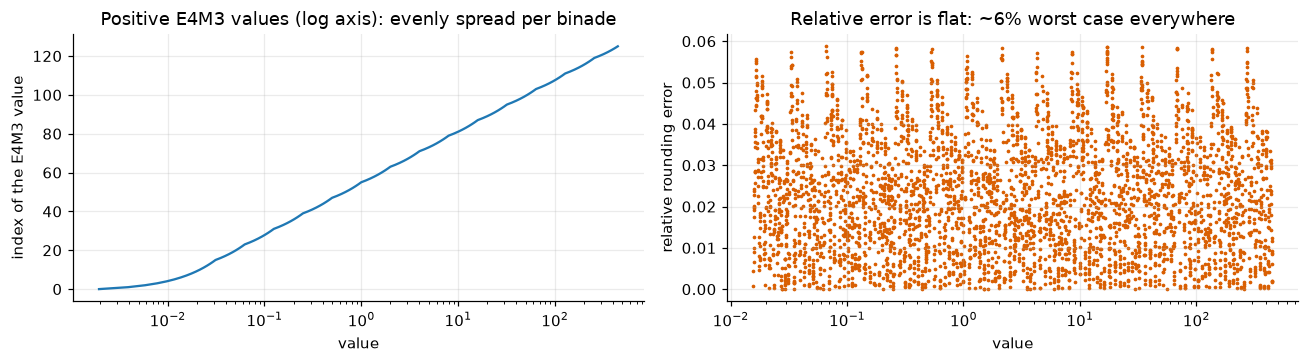

PASS - E4M3 has 253 distinct finite values 
PASS - largest value is 448 
PASS - worst relative rounding error is just under 2^-4 = 6.25% (the bound is reached at binade midpoints) 


In [2]:
bits = torch.arange(256, dtype=torch.uint8)
vals = bits.view(torch.float8_e4m3fn).float()
finite = vals[torch.isfinite(vals)]
pos = torch.unique(finite[finite > 0])
print(f"bit patterns 256; NaN {int((~torch.isfinite(vals)).sum())}; distinct finite values {len(torch.unique(finite))}")
print(f"largest {float(pos.max()):.0f}   smallest normal {float(pos[pos >= 2**-6].min()):.5f} (= 2^-6)   smallest subnormal {float(pos.min()):.6f} (= 2^-9)")
print(f"dynamic range: 448 / 2^-9 = {448 / 2**-9:,.0f}  (about {math.log2(448 / 2**-9):.1f} binades)")

# measured rounding error across the range
x = torch.exp(torch.empty(200000).uniform_(math.log(2**-6), math.log(448)))
q = x.to(torch.float8_e4m3fn).float()
rel = ((q - x).abs() / x)
print(f"worst relative rounding error for values in [2^-6, 448]: {float(rel.max()):.4f}   mean {float(rel.mean()):.4f}")

e5 = torch.arange(256, dtype=torch.uint8).view(torch.float8_e5m2).float()
e5 = e5[torch.isfinite(e5)]
print(f"for comparison E5M2: largest {float(e5.max()):.0f}, smallest subnormal {float(e5[e5 > 0].min()):.2e}, but only 2 mantissa bits")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(pos.numpy(), np.arange(len(pos)), color=C["blue"]); ax[0].set(xscale="log", xlabel="value", ylabel="index of the E4M3 value", title="Positive E4M3 values (log axis): evenly spread per binade")
order = rel.argsort(); ax[1].scatter(x[:4000].numpy(), rel[:4000].numpy(), s=2, color=C["orange"])
ax[1].set(xscale="log", xlabel="value", ylabel="relative rounding error", title="Relative error is flat: ~6% worst case everywhere")
plt.tight_layout(); plt.show()
check("E4M3 has 253 distinct finite values", len(torch.unique(finite)) == 253)
check("largest value is 448", float(pos.max()) == 448.0)
check("worst relative rounding error is just under 2^-4 = 6.25% (the bound is reached at binade midpoints)", 0.05 < float(rel.max()) <= 0.0625 + 1e-6)

The relative error is the same (at most 6.25%) over the whole range from $2^{-6}$ to 448. So **precision is not the problem**; **range is**. Anything larger than 448 overflows. Anything smaller than about $2^{-9} = 0.002$ becomes zero. The span between is about 17.8 binades (a factor of 230,000), which sounds like a lot, until a tensor holds both very large and very small numbers.

To use FP8 at all, a tensor $x$ is first multiplied by a **scale** so that its largest absolute value lands on the largest FP8 value, 448; after the multiplication it is rounded to FP8. The scale is stored and undone after the matrix multiplication. The standard practice (paper, section 3.3.2) uses **one scale for the whole tensor**: $s = \max|x| / 448$.

## 2. When one scale per tensor breaks

With one scale per tensor, the largest element sets the scale for everybody. If a single outlier is 100,000 times larger than typical values, then typical values get divided by a huge $s$ and fall below the smallest representable number. Two situations make this happen in transformers: an **outlier channel** (one feature dimension that is very large in every token) and **tokens whose overall magnitude differs** (some tokens have a much larger norm than others).

The paper's remedy is to scale **small groups**: activations in $1\times128$ **tiles** (one scale per token per 128 channels) and weights in $128\times128$ **blocks**. Each tile then adapts to its own maximum.

![Paper Figure 7(a): fine-grained quantization. The input is cut into 1xN_C tiles each with its own scale; the weight into N_C x N_C blocks; the scaled partial products are combined on the CUDA cores.](../../assets/deepseek_v3/fig7_finegrained.png)

*Figure 7 of the paper. Left: activations get one scaling factor per $1\times N_C$ tile, weights one per $N_C\times N_C$ block ($N_C=128$); the multiplication of the quantised tiles runs on the Tensor Core, and the product of the two scales is applied afterwards on the CUDA cores. Right: the accumulation promotion of step 5.*

Quantisation and its inverse, as the kit does them:

In [3]:
FP8_MAX = 448.0                      # largest finite E4M3 value

def quant_tile(x, tile: int = 128):
    """Activations: one scale per 1 x `tile` group along the last (contraction) dim.  x: (M, K), K % tile == 0."""
    M, K = x.shape
    g = x.reshape(M, K // tile, tile)
    s = (g.abs().amax(-1) / FP8_MAX).clamp_min(1e-12)                    # (M, K/tile)
    q = (g / s.unsqueeze(-1)).clamp(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)   # values now fit E4M3
    return q.reshape(M, K), s


def quant_block(w, blk: int = 128):
    """Weights: one scale per blk x blk block.  w: (N, K).  Returns fp8 (N,K) and scales (N/blk, K/blk)."""
    N, K = w.shape
    g = w.reshape(N // blk, blk, K // blk, blk)
    s = (g.abs().amax(dim=(1, 3)) / FP8_MAX).clamp_min(1e-12)            # (N/blk, K/blk)
    q = (g / s[:, None, :, None]).clamp(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)
    return q.reshape(N, K), s


def quant_tensor(x):
    """The 'standard practice' baseline: ONE scale for the whole tensor."""
    s = (x.abs().max() / FP8_MAX).clamp_min(1e-12)
    return (x / s).clamp(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn), s


def dequant_tile(q, s, tile: int = 128):
    M, K = q.shape
    return (q.float().reshape(M, K // tile, tile) * s.unsqueeze(-1)).reshape(M, K)


def dequant_block(q, s, blk: int = 128):
    N, K = q.shape
    return (q.float().reshape(N // blk, blk, K // blk, blk) * s[:, None, :, None]).reshape(N, K)

Now measure the damage. First the outlier channel: one channel multiplied by $m$ in every token, and the relative error on all the **other** channels (the ones that should be unaffected). Then tokens of widely different magnitude: each token scaled by a random factor spanning a given number of decades; we report the error on the **smallest tokens**.

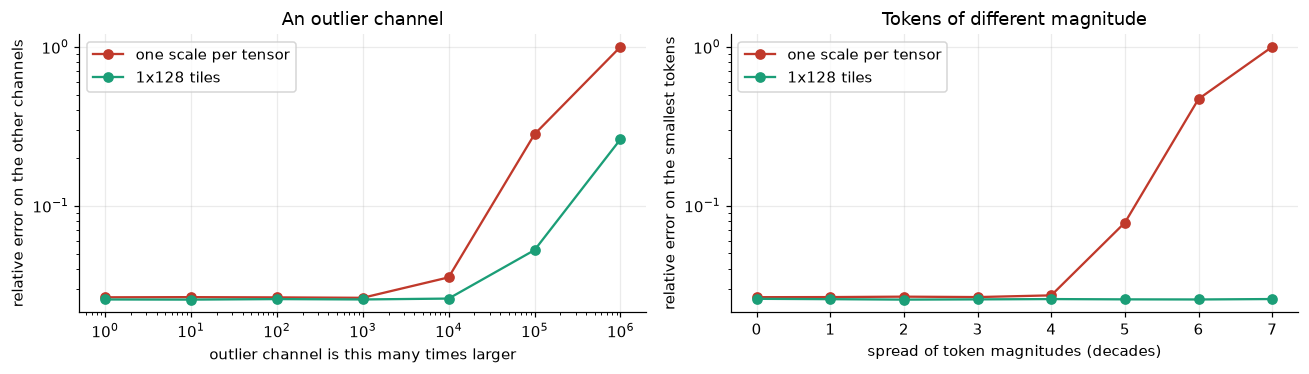

outlier channel x100000 : per-tensor error 0.282, tile error 0.053
token spread 7 decades: per-tensor error on small tokens 1.000, tile error 0.026
PASS - with no outlier both are accurate (about 2-3%) 
PASS - moderate outliers (x1000) do NOT break per-tensor scaling: E4M3's range is wide 
PASS - a x100000 outlier channel breaks per-tensor scaling (error > 20%) (0.28)
PASS - tiles stay accurate for the same outlier (0.05)
PASS - tokens spread over 7 decades: per-tensor scaling loses the small tokens (error > 90%), tiles stay under 4% 
PASS - at 5 decades per-tensor scaling is still usable but visibly worse than tiles (error 3x higher) 


In [4]:
def err_on(x, deq, mask):
    return float(((deq - x)[mask]).norm() / x[mask].norm())

torch.manual_seed(0)
mults = [1, 10, 1e2, 1e3, 1e4, 1e5, 1e6]
e_tensor, e_tile = [], []
for m in mults:
    x = torch.randn(64, 1024); x[:, 5] *= m
    mask = torch.ones(1024, dtype=torch.bool); mask[5] = False
    qt, st = quant_tensor(x); qg, sg = quant_tile(x)
    e_tensor.append(err_on(x, qt.float() * st, mask.expand_as(x)))
    e_tile.append(err_on(x, dequant_tile(qg, sg), mask.expand_as(x)))

decades = [0, 1, 2, 3, 4, 5, 6, 7]
s_tensor, s_tile = [], []
for dec in decades:
    x = torch.randn(256, 1024) * (10 ** (dec * torch.rand(256, 1)))             # token scales spread over `dec` decades
    small = (x.abs().amax(1) < x.abs().amax(1).quantile(0.2)).unsqueeze(1).expand_as(x)   # the smallest 20% of tokens
    qt, st = quant_tensor(x); qg, sg = quant_tile(x)
    s_tensor.append(err_on(x, qt.float() * st, small)); s_tile.append(err_on(x, dequant_tile(qg, sg), small))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(mults, e_tensor, "o-", color=C["red"], label="one scale per tensor"); ax[0].plot(mults, e_tile, "o-", color=C["green"], label="1x128 tiles")
ax[0].set(xscale="log", yscale="log", xlabel="outlier channel is this many times larger", ylabel="relative error on the other channels", title="An outlier channel"); ax[0].legend()
ax[1].plot(decades, s_tensor, "o-", color=C["red"], label="one scale per tensor"); ax[1].plot(decades, s_tile, "o-", color=C["green"], label="1x128 tiles")
ax[1].set(yscale="log", xlabel="spread of token magnitudes (decades)", ylabel="relative error on the smallest tokens", title="Tokens of different magnitude"); ax[1].legend()
plt.tight_layout(); plt.show()
print("outlier channel x%g : per-tensor error %.3f, tile error %.3f" % (mults[-2], e_tensor[-2], e_tile[-2]))
print("token spread %d decades: per-tensor error on small tokens %.3f, tile error %.3f" % (decades[7], s_tensor[7], s_tile[7]))
check("with no outlier both are accurate (about 2-3%)", e_tensor[0] < 0.04 and e_tile[0] < 0.04)
check("moderate outliers (x1000) do NOT break per-tensor scaling: E4M3's range is wide", e_tensor[3] < 0.04)
check("a x100000 outlier channel breaks per-tensor scaling (error > 20%)", e_tensor[5] > 0.2, "(%.2f)" % e_tensor[5])
check("tiles stay accurate for the same outlier", e_tile[5] < 0.12, "(%.2f)" % e_tile[5])
check("tokens spread over 7 decades: per-tensor scaling loses the small tokens (error > 90%), tiles stay under 4%", s_tensor[7] > 0.9 and s_tile[7] < 0.04)
check("at 5 decades per-tensor scaling is still usable but visibly worse than tiles (error 3x higher)", s_tensor[5] > 3 * s_tile[5])

Read the left plot honestly: E4M3's range is wide enough that a single outlier channel has to be $10^4$ times larger than the rest before per-tensor scaling hurts, and the tile method is also affected at very large factors, because the tile that contains the outlier channel still has to share one scale among its 128 elements. Whether real activations in a 671B model reach such ratios is a statement about that model; the paper's claim is that outliers in activations, weights and gradients limit low-precision training. The right plot is the more common failure: a tensor that mixes tokens of very different magnitude. With a spread of about six decades per-tensor scaling starts to lose the small tokens, and at seven it flushes them to zero; per-token scales do not care.

## 3. Why these shapes: activations 1x128, weights 128x128

Scale groups run along the **inner (contraction) dimension** of the matrix product, so that the scale can be applied to a partial sum of 128 products (step 4). For activations $X\in\mathbb R^{M\times K}$ that means one scale per token per 128 channels. For weights $W\in\mathbb R^{N\times K}$, DeepSeek uses **square** blocks. There is a reason, and we can check it: the backward pass needs $W^\top$, and a square block grid quantises $W^\top$ to exactly the transpose of what it did to $W$, so the same FP8 weights serve the forward and the backward pass. Tiles along one axis do not have this property.

In [5]:
torch.manual_seed(0)
W = torch.randn(256, 384)
qW, sW = quant_block(W)                    # W: (256, 384)
qWt, sWt = quant_block(W.t().contiguous())  # W^T: (384, 256), quantised from scratch
same_vals = torch.equal(qW.float().t(), qWt.float())
same_scales = torch.equal(sW.t(), sWt)
print("blocks: quantising W^T from scratch gives the transpose of quantising W:", same_vals and same_scales)

qa, sa = quant_tile(W)                      # 1x128 tiles along rows
qat, sat = quant_tile(W.t().contiguous())   # 1x128 tiles of W^T: different groups of elements
print("tiles : the same is true for 1x128 tiles?", torch.equal(qa.float().t(), qat.float()))
print("        fraction of elements that quantise to a different FP8 value: %.1f%%" % (100 * float((qa.float().t() != qat.float()).float().mean())))
check("128x128 blocks are transposition-invariant", same_vals and same_scales)
check("1x128 tiles are not", not torch.equal(qa.float().t(), qat.float()))

blocks: quantising W^T from scratch gives the transpose of quantising W: True
tiles : the same is true for 1x128 tiles? False
        fraction of elements that quantise to a different FP8 value: 81.6%
PASS - 128x128 blocks are transposition-invariant 
PASS - 1x128 tiles are not 


Activations and gradients are not reused transposed (the backward pass needs them grouped along a *different* axis, so it re-quantises them from the stored higher-precision tensor), which is why per-token tiles are fine for them, and why the paper keeps weights in blocks.

## 4. The matrix product with per-group scales

The product $C = A B^\top$ with $A$ in tiles and $B$ in blocks is a sum over $K$. Cut $K$ into groups of 128. Inside group $g$ every element of $A$'s row has the same scale $a_g$ and every element of $B$'s row the same scale $b_g$, so

$$ C = \sum_{g} \underbrace{\big(A^q_{g}\,B^{q\top}_{g}\big)}_{\text{FP8 product, Tensor Core}} \cdot a_g\, b_g . $$

The paper's hardware does the bracket on the Tensor Core and the multiplication by the two scales (the "dequantisation") on the CUDA cores, adding into an FP32 sum. This is the structure of `fp8_gemm`. The second function, `accumulate_limited`, is the subject of the next step; with `acc_bits=None` it accumulates exactly. First check that with exact accumulation the structure is right:

In [6]:
def round_sig_bits(x, bits: int):
    """Keep only `bits` significant bits (emulates a narrow accumulator register)."""
    m, e = torch.frexp(x)
    return torch.ldexp(torch.round(m * 2.0 ** bits) / 2.0 ** bits, e)


def accumulate_limited(a, b, interval: int, mma_k: int = 32, acc_bits: int | None = 14):
    """a @ b.T where a Tensor-Core-like accumulator keeps only `acc_bits` significant bits.

    The K axis is cut into MMA steps of `mma_k`.  After every `interval` elements the accumulator is
    promoted: added to an FP32 running sum and cleared.  acc_bits=None -> exact FP32 everywhere.
    """
    M, K = a.shape
    total = torch.zeros(M, b.shape[0])
    for k0 in range(0, K, interval):
        acc = torch.zeros(M, b.shape[0])
        for k1 in range(k0, min(k0 + interval, K), mma_k):                              # one MMA instruction
            part = a[:, k1:k1 + mma_k] @ b[:, k1:k1 + mma_k].t()
            acc = acc + part if acc_bits is None else round_sig_bits(acc + part, acc_bits)
        total = total + acc                                                             # promotion to FP32
    return total


def fp8_gemm(aq, sa, bq, sb, interval: int = 128, mma_k: int = 32, acc_bits: int | None = 14, group: int = 128):
    """C = A @ B^T from FP8 operands with per-group scales along K  (paper Fig. 7).

    aq (M,K) fp8, sa (M,K/group)    bq (N,K) fp8, sb (N,K/group) (block scales already expanded per row).
    Each scale group is accumulated on the narrow accumulator, then multiplied by both scales and added to an FP32 sum.
    """
    assert group % interval == 0, "the promotion interval must divide the scale group"
    a, b = aq.float(), bq.float()
    out = torch.zeros(a.shape[0], b.shape[0])
    for gi in range(a.shape[1] // group):
        sl = slice(gi * group, (gi + 1) * group)
        part = accumulate_limited(a[:, sl], b[:, sl], interval, mma_k, acc_bits)
        out = out + part * sa[:, gi:gi + 1] * sb[:, gi].unsqueeze(0)                    # dequantise on "CUDA cores", FP32
    return out

In [7]:
torch.manual_seed(0)
A, Bm = torch.randn(48, 512), torch.randn(64, 512)
aq, sa = quant_tile(A)
bq, sb = quant_tile(Bm)
ref = dequant_tile(aq, sa) @ dequant_tile(bq, sb).t()                     # dequantise first, then ordinary matmul
got = fp8_gemm(aq, sa, bq, sb, acc_bits=None)                             # scales applied per group, FP32 accumulation
print("max |grouped-scale GEMM - dequantise-then-matmul| =", float((got - ref).abs().max()))
exact = A @ Bm.t()
print("relative error of the FP8 product vs FP32:  RMS %.4f" % float((got - exact).norm() / exact.norm()))
check("per-group scaling GEMM equals dequantise-then-matmul", torch.allclose(got, ref, atol=1e-3, rtol=1e-4))
check("FP8 product is within 5% (RMS) of the FP32 product", float((got - exact).norm() / exact.norm()) < 0.05)

max |grouped-scale GEMM - dequantise-then-matmul| = 6.103515625e-05
relative error of the FP8 product vs FP32:  RMS 0.0354
PASS - per-group scaling GEMM equals dequantise-then-matmul 
PASS - FP8 product is within 5% (RMS) of the FP32 product 


## 5. Accumulation precision

A Tensor Core multiplies and adds in a fixed-width internal accumulator. The paper reports that on the H800 the FP8 accumulator keeps only about **14 bits** of precision, much less than FP32's 24. For a long inner dimension $K$ the running sum grows large compared with each new term; the bits of the new term that do not fit are lost. The paper measured, for two random matrices with $K=4096$, a **maximum relative error near 2%**.

The remedy (Figure 7b): do the multiply-accumulate on the Tensor Core only over short intervals of $N_C = 128$ elements, then **copy the partial sum to FP32 registers** and keep summing there. The scales are applied at the same moment.

![Paper Figure 7: (b) on the right is the accumulation promotion. Every N_C = 128 elements the Tensor Core's low-precision partial sum is promoted to an FP32 register on the CUDA core.](../../assets/deepseek_v3/fig7_finegrained.png)

*Figure 7(b), right panel: WGMMA instructions accumulate in the Tensor Core's narrow register; at an interval of  = 128$ elements the partial result is copied to an FP32 register on the CUDA cores, where it is multiplied by the scaling factors and added into the full-precision sum.*

We cannot run an H800, so we **emulate a narrow accumulator**: after every MMA step (32 elements of $K$) the running sum is rounded to `acc_bits` significant bits. The value 14 and the step size 32 are our assumptions, taken from the paper's description; the real hardware behaviour is more intricate. The question we can answer is the qualitative one: how does the error depend on how often the partial sum is promoted?

In [8]:
print("what rounding to N significant bits does to a number:")
for v in [1.0 + 2 ** -10, 1234.5678]:
    print(f"   {v!r:>22}  ->  {[float(round_sig_bits(torch.tensor(v), b)) for b in (24, 14, 8)]}   (24, 14, 8 bits)")

torch.manual_seed(0)
Ka = 4096
a8 = torch.randn(32, Ka).to(torch.float8_e4m3fn).float(); b8 = torch.randn(32, Ka).to(torch.float8_e4m3fn).float()   # values ARE FP8
exact = (a8.double() @ b8.double().t()).float()
rows = []
for interval in [4096, 1024, 512, 128, 32]:
    got = accumulate_limited(a8, b8, interval=interval, acc_bits=14)
    rel = (got - exact).abs() / exact.abs().clamp_min(1e-9)
    rms = float((got - exact).norm() / exact.norm())
    rows.append((interval, float(rel.max()), float(rel.median()), rms))
    print(f"promote every {interval:5d}: max relative error {100 * float(rel.max()):7.2f}%   median {100 * float(rel.median()):.3f}%   RMS error / RMS value {100 * rms:.4f}%")
fp32 = accumulate_limited(a8, b8, interval=Ka, acc_bits=None)
print(f"FP32 accumulation        : RMS error {100 * float((fp32 - exact).norm() / exact.norm()):.6f}%")

what rounding to N significant bits does to a number:
             1.0009765625  ->  [1.0009765625, 1.0009765625, 1.0]   (24, 14, 8 bits)
                1234.5678  ->  [1234.5677490234375, 1234.625, 1232.0]   (24, 14, 8 bits)
promote every  4096: max relative error    4.02%   median 0.017%   RMS error / RMS value 0.0207%
promote every  1024: max relative error    6.44%   median 0.009%   RMS error / RMS value 0.0105%
promote every   512: max relative error    3.28%   median 0.007%   RMS error / RMS value 0.0076%
promote every   128: max relative error    1.86%   median 0.004%   RMS error / RMS value 0.0041%
promote every    32: max relative error    1.70%   median 0.003%   RMS error / RMS value 0.0027%
FP32 accumulation        : RMS error 0.000005%


In [9]:
check("promoting more often reduces the RMS error (4096 > 512 > 128 > 32)", rows[0][3] > rows[2][3] > rows[3][3] > rows[4][3])
check("the 128-element promotion cuts the RMS error by more than 4x relative to never promoting", rows[0][3] > 4 * rows[3][3], "(%.4f%% -> %.4f%%)" % (100 * rows[0][3], 100 * rows[3][3]))
check("FP32 accumulation is essentially exact", float((fp32 - exact).norm() / exact.norm()) < 1e-6)
print("our emulated max relative error with no promotion: %.1f%%  (paper's hardware measurement: ~2%%)" % (100 * rows[0][1]))

PASS - promoting more often reduces the RMS error (4096 > 512 > 128 > 32) 
PASS - the 128-element promotion cuts the RMS error by more than 4x relative to never promoting (0.0207% -> 0.0041%)
PASS - FP32 accumulation is essentially exact 
our emulated max relative error with no promotion: 4.0%  (paper's hardware measurement: ~2%)


Two readings. The RMS error is the honest summary: it falls steadily as the promotion interval shrinks, and 128 recovers most of the benefit (the paper chooses 128 as "the minimal interval that significantly improves precision without introducing overhead", because each promotion costs a few instructions). The **maximum** relative error is dominated by output entries that happen to be near zero, where any absolute error is a large fraction of a tiny value; our emulated figure differs from the paper's 2% because our accumulator model is not their hardware, and we do not claim to match it.

## 6. A full FP8 linear layer

A linear layer $Y = XW^\top$ has three matrix products in training (paper Figure 6): **Fprop** $Y = XW^\top$, **Dgrad** $dX = dY\,W$ and **Wgrad** $dW = dY^\top X$. DeepSeek-V3 runs all three in FP8, with FP32 master weights outside. Each product needs its operands grouped along **its own** contraction axis:

| GEMM | contracts over | $A$ operand | $B$ operand |
|---|---|---|---|
| Fprop | input features $K$ | $X$ in 1x128 tiles | $W$ in 128x128 blocks |
| Dgrad | output features $N$ | $dY$ in 1x128 tiles | $W^\top$ in 128x128 blocks |
| Wgrad | tokens $M$ | $dY^\top$ in 1x128 tiles | $X^\top$ in 1x128 tiles |

![Paper Figure 6: the FP8 data flow of one Linear operator. Fprop, Dgrad and Wgrad all take FP8 inputs and produce BF16 or FP32 outputs; master weights and optimizer states stay in higher precision.](../../assets/deepseek_v3/fig6_fp8_framework.png)

*Figure 6 of the paper. Input, weight and output gradient are cast to FP8 before each of the three GEMMs; sums are accumulated in FP32; master weights, weight gradients and optimizer states are kept in higher precision.*

All quantised inputs are E4M3 (the paper does not use E5M2 for gradients, which earlier FP8 recipes did). A custom autograd function implements the table; padding handles dimensions that are not multiples of 128.

In [10]:
from dsv3kit import fp8_matmul_nt   # helper: pads to multiples of 128, picks tile or block scaling

class _FP8LinearFn(torch.autograd.Function):
    """Linear layer whose three GEMMs (Fprop, Dgrad, Wgrad) all run on E4M3 operands (paper Fig. 6)."""

    @staticmethod
    def forward(ctx, x, w, acc_bits):
        ctx.save_for_backward(x, w)
        ctx.acc_bits = acc_bits
        # Fprop: Y = X W^T      contraction over K=in_features: X in 1x128 tiles, W in 128x128 blocks
        return fp8_matmul_nt(x, w, b_is_weight_block=True, acc_bits=acc_bits)[:, : w.shape[0]]

    @staticmethod
    def backward(ctx, dy):
        x, w = ctx.saved_tensors
        # Dgrad: dX = dY W      contraction over N=out_features: dY in 1x128 tiles, W^T in 128x128 blocks
        dx = fp8_matmul_nt(dy, w.t().contiguous(), b_is_weight_block=True, acc_bits=ctx.acc_bits)[:, : x.shape[1]]
        # Wgrad: dW = dY^T X    contraction over M=tokens: both operands in 1x128 tiles along the token axis
        dw = fp8_matmul_nt(dy.t().contiguous(), x.t().contiguous(), b_is_weight_block=False, acc_bits=ctx.acc_bits)
        return dx, dw[: w.shape[0], : w.shape[1]], None


class FP8Linear(nn.Module):
    """Master weights stay FP32; every matmul sees E4M3 tensors with fine-grained scales."""

    def __init__(self, d_in, d_out, acc_bits: int | None = 14):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(d_out, d_in) * d_in ** -0.5)
        self.acc_bits = acc_bits

    def forward(self, x):
        lead = x.shape[:-1]
        y = _FP8LinearFn.apply(x.reshape(-1, x.shape[-1]), self.weight, self.acc_bits)
        return y.reshape(*lead, -1)

In [11]:
torch.manual_seed(1)
lin = FP8Linear(300, 200)                                    # deliberately not multiples of 128: padding is exercised
x = torch.randn(150, 300, requires_grad=True)
y = lin(x); ref = x @ lin.weight.t()
dy = torch.randn_like(y)
y.backward(dy)
dx_ref, dw_ref = dy @ lin.weight.detach(), dy.t() @ x.detach()
rel = lambda a, b: float((a - b).norm() / b.norm())
print(f"Fprop relative error {rel(y, ref):.4f}   Dgrad {rel(x.grad, dx_ref):.4f}   Wgrad {rel(lin.weight.grad, dw_ref):.4f}")
check("Fprop within 5% of FP32", rel(y, ref) < 0.05)
check("Dgrad within 6% of FP32", rel(x.grad, dx_ref) < 0.06)
check("Wgrad within 6% of FP32", rel(lin.weight.grad, dw_ref) < 0.06)
check("shapes are preserved through padding", y.shape == (150, 200) and x.grad.shape == x.shape and lin.weight.grad.shape == lin.weight.shape)

Fprop relative error 0.0368   Dgrad 0.0364   Wgrad 0.0361
PASS - Fprop within 5% of FP32 
PASS - Dgrad within 6% of FP32 
PASS - Wgrad within 6% of FP32 
PASS - shapes are preserved through padding 


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_54544/3828150957.py:8: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  rel = lambda a, b: float((a - b).norm() / b.norm())


## 7. Training with it

Does a network learn normally when every matrix product is quantised? The paper reports that the relative loss error of FP8 against BF16 training stays below 0.25% over about 1 trillion tokens on two model scales. Our version: a small teacher-student regression with three linear layers, trained three ways with identical data and initialisation:

- **FP32**: ordinary arithmetic;
- **BF16**: inputs and weights rounded to bfloat16 before each product (simulated);
- **FP8**: the layer of step 6 (fine-grained scales, 14-bit accumulator emulation, 128-element promotion).

In [12]:
class BF16Linear(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__(); self.weight = nn.Parameter(torch.randn(d_out, d_in) * d_in ** -0.5)
    def forward(self, x):
        return (x.bfloat16() @ self.weight.bfloat16().t()).float()

class FP32Linear(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__(); self.weight = nn.Parameter(torch.randn(d_out, d_in) * d_in ** -0.5)
    def forward(self, x):
        return x @ self.weight.t()

def make_net(Lin, seed):
    torch.manual_seed(seed)
    return nn.Sequential(Lin(64, 256), nn.GELU(), Lin(256, 256), nn.GELU(), Lin(256, 64))

def run(Lin, seed, steps=300):
    net = make_net(Lin, seed)
    teacher = make_net(FP32Linear, 1000)                        # the same teacher for every run
    for p in teacher.parameters(): p.requires_grad_(False)
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    gen = torch.Generator().manual_seed(seed + 1)
    for _ in range(steps):
        x = torch.randn(256, 64, generator=gen)
        loss = F.mse_loss(net(x), teacher(x))
        opt.zero_grad(); loss.backward(); opt.step()
    xv = torch.randn(2048, 64, generator=torch.Generator().manual_seed(555))
    with torch.no_grad():
        return float(F.mse_loss(net(xv), teacher(xv)))

t0 = time.time()
out7 = {}
for name, Lin in [("FP32", FP32Linear), ("BF16", BF16Linear), ("FP8", FP8Linear)]:
    out7[name] = np.array([run(Lin, s) for s in range(3)])
    print(f"{name:5s} final val MSE {out7[name].mean():.5f} +- {out7[name].std():.5f}   (3 seeds)")
print("time %.0f s" % (time.time() - t0))

FP32  final val MSE 0.03465 +- 0.00030   (3 seeds)


BF16  final val MSE 0.03465 +- 0.00030   (3 seeds)


FP8   final val MSE 0.03494 +- 0.00030   (3 seeds)
time 88 s


In [13]:
rel_bf = (out7["BF16"].mean() - out7["FP32"].mean()) / out7["FP32"].mean()
rel_f8 = (out7["FP8"].mean() - out7["FP32"].mean()) / out7["FP32"].mean()
print(f"relative loss difference vs FP32: BF16 {100 * rel_bf:+.1f}%   FP8 {100 * rel_f8:+.1f}%")
init_mse = float(F.mse_loss(make_net(FP32Linear, 0)(torch.randn(2048, 64)), make_net(FP32Linear, 1000)(torch.randn(2048, 64))))
print(f"initial MSE for reference: {init_mse:.3f}   seed spread of the FP32 runs: {100 * out7['FP32'].std() / out7['FP32'].mean():.1f}% of their mean")
check("all three precisions reduce the error at least 5x from its initial value", all(v.mean() < init_mse / 5 for v in out7.values()))
check("FP8 ends within 25% of the FP32 loss on this problem", abs(rel_f8) < 0.25, "(%+.1f%%)" % (100 * rel_f8))

relative loss difference vs FP32: BF16 +0.0%   FP8 +0.9%
initial MSE for reference: 0.294   seed spread of the FP32 runs: 0.9% of their mean
PASS - all three precisions reduce the error at least 5x from its initial value 
PASS - FP8 ends within 25% of the FP32 loss on this problem (+0.9%)


All three precisions reach the same plateau (about 0.035, from an initial 0.29). FP8 ends about 1% above FP32, about one seed-spread, and BF16 is indistinguishable from FP32 at this precision. That is the same order as the paper's claim that FP8 stays within 0.25% of BF16, but we cannot test that number: ours is three seeds on a toy regression, where a gap of a fraction of a percent cannot be resolved, and the paper's figure is for about 1T tokens and models of billions of parameters. What the experiment does support is the qualitative statement: training through all three FP8 GEMMs, with fine-grained scales and FP32 master weights, converges to the same loss level as FP32 and BF16.

## 8. Memory accounting, and what stays in high precision

The scales cost memory too. One FP32 scale per 128 activations adds $32/128 = 0.25$ bits per element; one per 128x128 weight block adds about 0.002 bits:

In [14]:
bits_act = 8 + 32 / 128
bits_w = 8 + 32 / (128 * 128)
print(f"activations: {bits_act:.3f} bits/element   weights: {bits_w:.4f} bits/element   (BF16: 16)")
print(f"memory ratio vs BF16: activations {16 / bits_act:.2f}x smaller, weights {16 / bits_w:.2f}x smaller")
check("tile scales cost 0.25 bits per activation element", abs(bits_act - 8.25) < 1e-9)
check("FP8 with scales is still almost 2x smaller than BF16", 16 / bits_act > 1.9)

activations: 8.250 bits/element   weights: 8.0020 bits/element   (BF16: 16)
memory ratio vs BF16: activations 1.94x smaller, weights 2.00x smaller
PASS - tile scales cost 0.25 bits per activation element 
PASS - FP8 with scales is still almost 2x smaller than BF16 


Not everything runs in FP8. The paper keeps these in BF16 or FP32: the **embedding**, the **output head**, the **MoE gating** modules, the **normalisation** operators and the **attention** operators; the **master weights, weight gradients and optimizer states** are stored in higher precision (and sharded across data-parallel ranks to hold the cost down). It also stores cached activations and dispatched MoE activations in FP8 and optimizer moments in BF16. These choices follow one rule: use FP8 for the large GEMMs, where the savings are, and keep high precision for the small, numerically sensitive operations.

The paper quantises **online**: it computes the maximum of each tile or block on the fly and derives the scale, instead of using a history of past maxima ("delayed quantisation") as some frameworks do. That is what our code does.

## What to take away

1. **E4M3 has good relative precision (6.25% worst case) and a wide but finite range (448 down to 0.002).** Scaling puts each group of numbers into that range.
2. **Fine-grained scales (1x128 tiles, 128x128 blocks) protect against mixed magnitudes**: tokens spread over many decades, or large outliers. Per-tensor scaling fails there (measured above) while holding up in benign cases.
3. **Square weight blocks are transposition-invariant**, so one quantised copy serves forward and backward.
4. **Promoting partial sums to FP32 every 128 elements** removes most of the accumulation error of a narrow accumulator.
5. **All three GEMMs of a linear layer can run in FP8** and training still converges, with master weights in FP32.

## What this notebook does not show
- **Speed.** Emulation is slower than FP32; the 2x throughput comes from FP8 Tensor Cores we do not have.
- **The real accumulator.** The 14-bit, 32-element-step model is our reading of the paper's description. We do not match the paper's 2% figure and do not claim to.
- **The paper's loss result.** Under 0.25% relative error against BF16 is for ~1T tokens; ours is a toy regression with three seeds (FP8 ended about 1% above FP32, one seed-spread).
- **The instability of block-wise activation quantisation** the paper reports in its appendix (it diverges for a large MoE model), which needs that model.

*Next:* notebook 6 is about DualPipe, the pipeline schedule.

In [15]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 24 | failed: 0
